<a href="https://colab.research.google.com/github/asepmuhidin/kriptografi/blob/main/fondasi_stego.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
from PIL import Image
from google.colab import files
import matplotlib.pyplot as plt

In [3]:
uploaded = files.upload()

Saving 134224575675659442.jpg to 134224575675659442.jpg


In [4]:
filename = list(uploaded.keys())[0]
filename

'134224575675659442.jpg'

In [8]:
citra = Image.open(filename)

In [9]:
# Menampilkan informasi gambar
print("Nama file :", filename)
print("Format    :", citra.format)
print("Mode      :", citra.mode)
print("Ukuran    :", citra.size)

Nama file : 134224575675659442.jpg
Format    : JPEG
Mode      : RGB
Ukuran    : (3840, 2160)


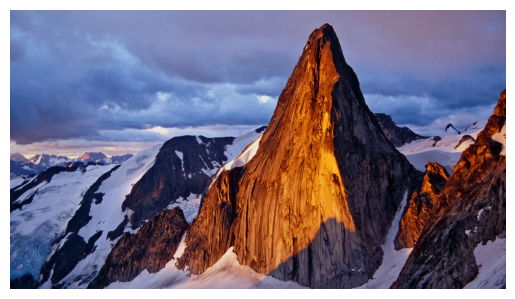

In [10]:
plt.imshow(citra)
plt.axis('off')
plt.show()

In [11]:
lebar, tinggi = citra.size
print(f"Lebar : {lebar}")
print(f"Tinggi : {tinggi}")

Lebar : 3840
Tinggi : 2160


In [15]:
larik_pixel=np.array(list(citra.getdata()))
larik_pixel.size

24883200

In [16]:
if citra.mode == 'RGB':
  n = 3

total_pixel = larik_pixel.size//n
total_pixel

8294400

In [17]:
pesan = "ini pesan yang ada di gambar"

In [18]:
pesan_biner = ''.join([format(ord(i), "08b") for i in pesan])
pesan_biner

'01101001011011100110100100100000011100000110010101110011011000010110111000100000011110010110000101101110011001110010000001100001011001000110000100100000011001000110100100100000011001110110000101101101011000100110000101110010'

In [19]:
jumlah_pixel_embed = len(pesan_biner)
jumlah_pixel_embed

224

In [20]:
if jumlah_pixel_embed > total_pixel:
  print("ERROR: Ukuran citra tidak mencukupi untuk penyembunyian pesan")
else:
  index=0
  for p in range(total_pixel):
    for q in range(0, 2):
      if index < jumlah_pixel_embed:
        larik_pixel[p][q] = int(bin(larik_pixel[p][q])[2:9] + pesan_biner[index], 2)
        index = index + 1


In [21]:
larik_pixel = larik_pixel.reshape(tinggi, lebar, n)
larik_pixel

array([[[242, 137, 193],
        [233, 132, 189],
        [217, 128, 184],
        ...,
        [117, 104, 134],
        [112,  96, 125],
        [105,  86, 116]],

       [[ 98, 113, 168],
        [104, 121, 175],
        [104, 125, 178],
        ...,
        [103,  90, 120],
        [106,  91, 122],
        [109,  93, 122]],

       [[ 98, 113, 168],
        [102, 119, 173],
        [102, 123, 176],
        ...,
        [103,  90, 120],
        [114,  99, 130],
        [126, 109, 141]],

       ...,

       [[  0,   1,  20],
        [  2,   7,  26],
        [  5,  10,  29],
        ...,
        [ 58,  55,  72],
        [ 64,  63,  79],
        [ 71,  70,  86]],

       [[  0,   3,  22],
        [  2,   7,  26],
        [  3,   8,  27],
        ...,
        [ 63,  60,  79],
        [ 69,  68,  86],
        [ 77,  76,  94]],

       [[  2,   5,  22],
        [  5,   8,  25],
        [  4,   7,  24],
        ...,
        [ 64,  61,  80],
        [ 69,  67,  88],
        [ 77,  75,  96]]

In [22]:
stego_image = Image.fromarray(larik_pixel.astype('uint8'), citra.mode)
stego_image.save("stego_image.jpeg")
print("Penyisipan pesan ke dalam citra berhasil")

Penyisipan pesan ke dalam citra berhasil


/tmp/ipykernel_517/3186550399.py:1: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  stego_image = Image.fromarray(larik_pixel.astype('uint8'), citra.mode)
